In [1]:
import sys
from pathlib import Path

current_path = Path.cwd()

if (current_path / "src").exists():
    PROJECT_ROOT = current_path
elif (current_path.parent / "src").exists():
    PROJECT_ROOT = current_path.parent
else:
    raise FileNotFoundError("No se encontró la carpeta src.")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

from src.models import CosCoshParams, CosCoshModel

Project root: /Users/macbook/Usach/TesisxD/cosmo_singularities


In [2]:
params = CosCoshParams(
    wa=5.203,
    wb=0.188,
    wc=3.634,
    rho0=1.0,
    a0=1.0,
    t0=0.0,
    H0=1.0,
)

model = CosCoshModel(params)

In [4]:
import numpy as np
import pandas as pd

x_values = np.linspace(0.0, 3.0, 2000)

df_cosh = model.evaluate_background_x(x_values)

df_cosh.head()

/Users/macbook/Usach/TesisxD/cosmo_singularities/src/models.py:1691: RuntimeWarning: overflow encountered in exp
  return self.params.rho0 * np.exp(-3.0 * G)
/Users/macbook/Usach/TesisxD/cosmo_singularities/src/models.py:1698: RuntimeWarning: overflow encountered in exp
  return self.params.H0 * np.exp(-1.5 * G)
/Users/macbook/Usach/TesisxD/cosmo_singularities/src/models.py:1746: RuntimeWarning: overflow encountered in multiply
  P_values = w_values * rho_values


,x,t,tau,a,w,G,rho,P,H
0,0.000000,0.000000,0.000000,1.000000,-1.112906,0.000000,1.000000,-1.112906,1.000000
1,0.001501,0.001501,0.001501,1.001502,-1.116041,-0.000172,1.000516,-1.116616,1.000258
2,0.003002,0.003001,0.003001,1.003006,-1.119208,-0.000348,1.001046,-1.120379,1.000523
3,0.004502,0.004500,0.004500,1.004512,-1.122408,-0.000530,1.001590,-1.124193,1.000795
4,0.006003,0.006000,0.006000,1.006021,-1.125641,-0.000716,1.002150,-1.128061,1.001074


In [5]:
df_cosh.tail()

,x,t,tau,a,w,G,rho,P,H
1995,2.993997,0.413807,0.413807,19.965325,-8.794973e+08,-4.405471e+07,inf,-inf,inf
1996,2.995498,0.413807,0.413807,19.995310,-9.076299e+08,-4.539573e+07,inf,-inf,inf
1997,2.996998,0.413807,0.413807,20.025341,-9.367046e+08,-4.677967e+07,inf,-inf,inf
1998,2.998499,0.413807,0.413807,20.055416,-9.667542e+08,-4.820798e+07,inf,-inf,inf
1999,3.000000,0.413807,0.413807,20.085537,-9.978130e+08,-4.968214e+07,inf,-inf,inf


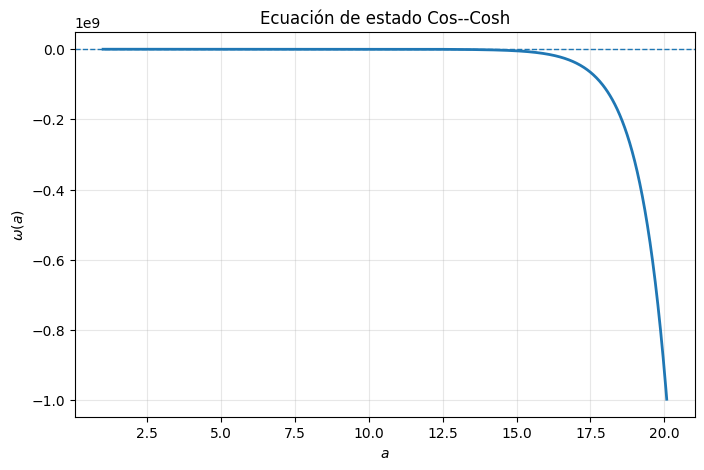

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(df_cosh["a"], df_cosh["w"], linewidth=2)

plt.axhline(-1.0, linestyle="--", linewidth=1)

plt.xlabel(r"$a$")
plt.ylabel(r"$\omega(a)$")
plt.title(r"Ecuación de estado Cos--Cosh")
plt.grid(True, alpha=0.3)
plt.show()

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/matplotlib/scale.py:270: RuntimeWarning: overflow encountered in power
  return np.power(self.base, values)


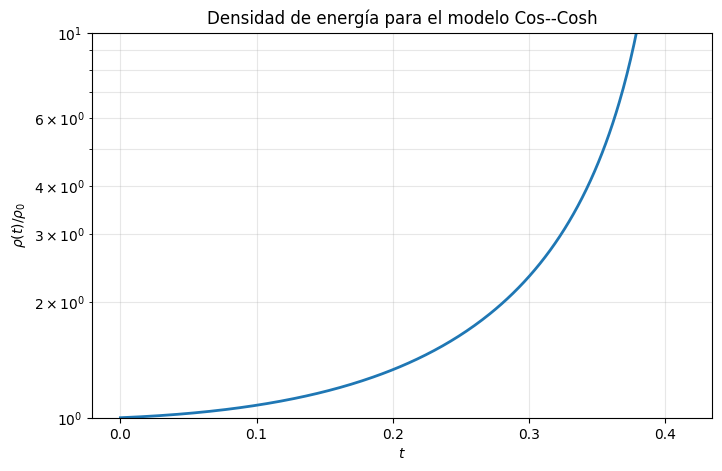

In [7]:
plt.figure(figsize=(8, 5))

plt.plot(df_cosh["t"], df_cosh["rho"], linewidth=2)

plt.yscale("log")
plt.xlabel(r"$t$")
plt.ylabel(r"$\rho(t)/\rho_0$")
plt.title(r"Densidad de energía para el modelo Cos--Cosh")
plt.grid(True, which="both", alpha=0.3)
plt.show()

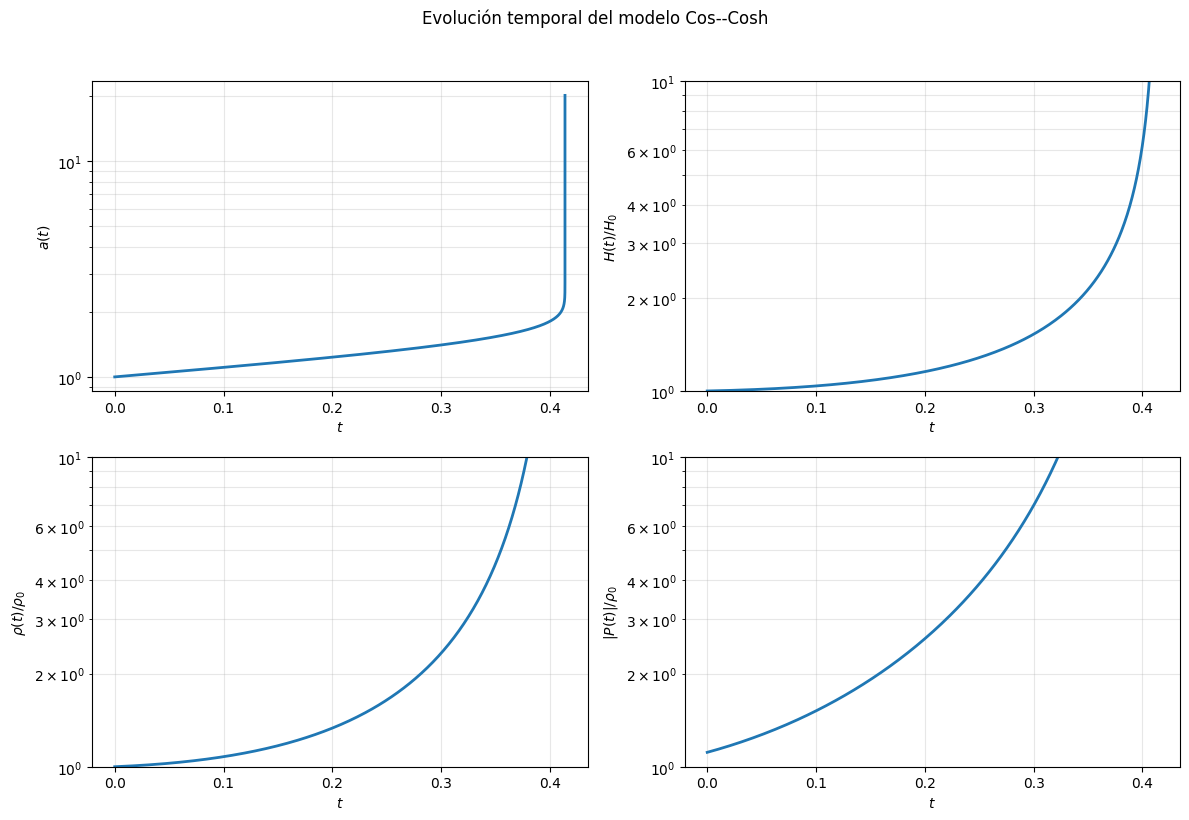

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].plot(df_cosh["t"], df_cosh["a"], linewidth=2)
axes[0, 0].set_ylabel(r"$a(t)$")

axes[0, 1].plot(df_cosh["t"], df_cosh["H"], linewidth=2)
axes[0, 1].set_ylabel(r"$H(t)/H_0$")

axes[1, 0].plot(df_cosh["t"], df_cosh["rho"], linewidth=2)
axes[1, 0].set_ylabel(r"$\rho(t)/\rho_0$")

axes[1, 1].plot(df_cosh["t"], np.abs(df_cosh["P"]), linewidth=2)
axes[1, 1].set_ylabel(r"$|P(t)|/\rho_0$")

for ax in axes.flatten():
    ax.set_xlabel(r"$t$")
    ax.set_yscale("log")
    ax.grid(True, which="both", alpha=0.3)

fig.suptitle(r"Evolución temporal del modelo Cos--Cosh", y=1.02)
plt.tight_layout()
plt.show()

In [9]:
ts_est = model.estimate_singular_time(
    x_max=6.0,
    n_points=5000,
)

ts_est

/Users/macbook/Usach/TesisxD/cosmo_singularities/src/models.py:1691: RuntimeWarning: overflow encountered in exp
  return self.params.rho0 * np.exp(-3.0 * G)
/Users/macbook/Usach/TesisxD/cosmo_singularities/src/models.py:1698: RuntimeWarning: overflow encountered in exp
  return self.params.H0 * np.exp(-1.5 * G)
/Users/macbook/Usach/TesisxD/cosmo_singularities/src/models.py:1746: RuntimeWarning: overflow encountered in multiply
  P_values = w_values * rho_values


0.413807050495297